# 🧪 LAB: Manual MLPs for Classification and Regression

In this lab, you will use `PyTorch` to implement manually a multi-layer perceptron (MLP) for three different tasks: binary classification, multi-class classification and regression.

## General instructions to complete in ALL three tasks:

1. ***IMPLEMENTATION***:
   
Implement a separate class for each task:

  - `BinaryMLP` for the binary classification task  
  - `MultiClassMLP` for the multi-class classification task  
  - `RegressionMLP` for the regression task

   Each class must include the following methods:

  - `__init__` for initializing 1 or 2 hidden layers. (*Help*: having a second hidden layer only means the need of having a extra set of weights and intercept).
  - `forward` to transfer information from the input to the output layer. (*Help*: make sure that information passes through a second hidden layer if there is one).
  - `cost` computing the cost.
  - `fit` for training, using the gradients to manually update the parameters of the model. **Use stochastic gradient descent to update your weights**. *N.B.* You may probably reuse much of the code we used in this week tutorial already.
  - `predict` to convert the information at the output layer into the required output.

2. ***DATA PREPARATION***

For each task, you will be provided with a toy dataset. For each dataset:

  - Split into training and holdout sets (use an 80/20 split)
  - Standardize the features properly, avoiding data leakage
  - Convert all data into `PyTorch` Tensors for compatibility

3. ***MODEL TRAINING AND EVALUATION***

Instantiate the model for each task and train it under different hyperparameter configurations. In each case, record the performance on **both** the training and holdout sets using the appropriate metric for the task (accuracy, MSE, etc.). You should explore the following configurations:

  - One hidden layer, varying the number of hidden units (use ReLU as their activation function)
  - Same number of hidden units across one or two hidden layers (use ReLU as their activation function)
  - Repeat the above setups using Tanh activation instead of ReLU

Present your results in a compact way (e.g., a summary table, a data frame etc).

**NOTE**: When training your model, use a fixed learning rate of your choice (e.g., 0.01 is a reasonable starting point) and a reasonably large number of  epochs (e.g., 100–200) based on how training and holdout performance evolve.

4. ***REFLECTION AND DISCUSSION***

Reflect on the impact of the different hyperparameter settings:

- How does the number of hidden units affect performance?
- What changes when using two layers instead of one?
- How does the activation function (ReLU vs. Tanh) influence results?

Please elaborate your answers.

---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

**Ideally, each group member should be responsible for one of the separate tasks.** BUT, everyone should help each other along the way, both reviewing and refining results and discussion.

---

In total, this lab assignment will be worth **100 points**.

---
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.


In [ ]:
NAME(s) = ""

## 1. Pre-implementation Group Discussion (15 points)

Discuss and agree on:

- What cost function should be used for each of the below task.
- What changes are needed in the output layer for each of these tasks. In particular, consider the number of units and the activation function.
- Why it is important to standardize the data before training each model.
- How you could detect overfitting when training your models.

USE AS MANY MARKDOWN CELLS AS NEEDED

## 2. Binary Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [ ]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=1000, noise=0.2, random_state=42)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 2. Multi-Class Classification (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

---
**NOTE**: This will likely be the most challenging exercise. To help you, here are some pointers:

 - The **output (last) layer** should have as many units as there are classes in your data.  

 - The **activation function of the output layer must be softmax**, not sigmoid. Softmax ensures that all output values are between 0 and 1 and sum to 1, so they can be interpreted as probabilities across the different classes. (*Help*: you may want to look into `torch.nn.functional` to find its implementation...)

 - For a multi-class problem, your target variable `y` should be **one-hot encoded**. For example:  
   - Label = 0 → [1, 0, 0]  
   - Label = 1 → [0, 1, 0]  
   - Label = 2 → [0, 0, 1]  
   You can easily achieve this with `OneHotEncoder` from `sklearn.preprocessing`.  

 - The **predicted class** corresponds to the unit with the highest probability.  
   Example:  
   - `[0.1, 0.3, 0.6] → class 2`  
   - `[0.6, 0.2, 0.2] → class 0`  

 - For this exercise, you need to **implement the categorical cross-entropy loss** (an extension of binary cross-entropy to multiple classes). It is defined as:  

   $$\sum_{c=1}^{l} y_{o,c}\,\log(p_{o,c}),$$

   where $l$ is the number of classes, $y_{o,c}$ is the one-hot encoded label for observation $o$, and $p_{o,c}$ is the predicted probability for class $c$ (after applying softmax). The log is the natural logarithm.

---

In [ ]:
from sklearn.datasets import make_classification

X, y = make_classification(n_samples=1000, n_classes=3,
                           n_clusters_per_class=1,
                           n_features=2, n_informative=2, n_redundant=0, random_state=1234, flip_y=0.15)

In [ ]:
# USE AS MANY CELLS AS NEEDED

## 3: Regression Task (25 points)

Use the dataset below to complete points 1 to 4 in the general instructions for this task.

Use as many cells as needed.

In [1]:
from sklearn.datasets import make_regression
X, y = make_regression(n_samples=1000, n_features=2, n_informative=2, random_state=1234, noise=75)

In [2]:
import torch
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

torch.manual_seed(1234)
np.random.seed(1234)

# 80/20 split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)

# Standardize features
x_scaler = StandardScaler().fit(X_train)
X_train_s = x_scaler.transform(X_train)
X_test_s = x_scaler.transform(X_test)

# Standardize target
y_scaler = StandardScaler().fit(y_train.reshape(-1, 1))
y_train_s = y_scaler.transform(y_train.reshape(-1, 1))
y_test_s = y_scaler.transform(y_test.reshape(-1, 1))

# Tensors
X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train_s, dtype=torch.float32)
y_test_t = torch.tensor(y_test_s, dtype=torch.float32)

print("Train:", X_train_t.shape, y_train_t.shape)
print("Holdout:", X_test_t.shape, y_test_t.shape)

Train: torch.Size([800, 2]) torch.Size([800, 1])
Holdout: torch.Size([200, 2]) torch.Size([200, 1])


In [3]:
class RegressionMLP:
    def __init__(self, n_inputs, n_hidden, n_layers=1, activation="relu", seed=1234):
        assert n_layers in (1, 2), "Only 1 or 2 hidden layers are supported"
        torch.manual_seed(seed)
        self.n_layers = n_layers
        self.activation_name = activation
        self.act = torch.relu if activation == "relu" else torch.tanh

        # Scaled random init keeps early activations in a reasonable range
        def init(n_in, n_out):
            W = (torch.randn(n_in, n_out) * np.sqrt(2.0 / n_in)).requires_grad_()
            b = torch.zeros(n_out, requires_grad=True)
            return W, b

        # First hidden layer
        self.W1, self.b1 = init(n_inputs, n_hidden)
        # Second hidden layer
        if n_layers == 2:
            self.W2, self.b2 = init(n_hidden, n_hidden)
        # Output layer
        self.W_out, self.b_out = init(n_hidden, 1)

    def parameters(self):
        params = [self.W1, self.b1]
        if self.n_layers == 2:
            params += [self.W2, self.b2]
        params += [self.W_out, self.b_out]
        return params

    def forward(self, X):
        h = self.act(X @ self.W1 + self.b1)
        if self.n_layers == 2:
            h = self.act(h @ self.W2 + self.b2)
        # Identity activation at the output for regression
        return h @ self.W_out + self.b_out

    def cost(self, y_pred, y_true):
        # Mean squared error
        return torch.mean((y_pred - y_true) ** 2)

    def fit(self, X, y, lr=0.01, epochs=200, batch_size=32, X_val=None, y_val=None):
        self.history = {"train_cost": [], "val_cost": []}
        n = X.shape[0]
        for epoch in range(epochs):
            perm = torch.randperm(n)
            for i in range(0, n, batch_size):
                idx = perm[i:i + batch_size]
                loss = self.cost(self.forward(X[idx]), y[idx])
                loss.backward()
                with torch.no_grad():
                    for p in self.parameters():
                        p -= lr * p.grad
                        p.grad.zero_()
            # Track cost on full train
            with torch.no_grad():
                self.history["train_cost"].append(self.cost(self.forward(X), y).item())
                if X_val is not None:
                    self.history["val_cost"].append(self.cost(self.forward(X_val), y_val).item())
        return self

    def predict(self, X):
        # The output unit already is the predicted value
        with torch.no_grad():
            return self.forward(X)

In [4]:
from sklearn.metrics import mean_squared_error, r2_score

def evaluate(model, X_t, y_true_original):
    pred_s = model.predict(X_t).numpy()
    pred = y_scaler.inverse_transform(pred_s).ravel()
    return mean_squared_error(y_true_original, pred), r2_score(y_true_original, pred)

hidden_units = [2, 4, 8, 16, 32, 64]
results = []
models = {}

for activation in ["relu", "tanh"]:
    for n_layers in [1, 2]:
        for h in hidden_units:
            model = RegressionMLP(n_inputs=2, n_hidden=h, n_layers=n_layers, activation=activation)
            model.fit(X_train_t, y_train_t, lr=0.01, epochs=200, batch_size=32,
                      X_val=X_test_t, y_val=y_test_t)
            tr_mse, tr_r2 = evaluate(model, X_train_t, y_train)
            te_mse, te_r2 = evaluate(model, X_test_t, y_test)
            results.append({
                "activation": activation, "hidden_layers": n_layers, "hidden_units": h,
                "train_MSE": round(tr_mse, 1), "holdout_MSE": round(te_mse, 1),
                "gap (holdout - train)": round(te_mse - tr_mse, 1),
                "train_R2": round(tr_r2, 3), "holdout_R2": round(te_r2, 3),
            })
            models[(activation, n_layers, h)] = model

results_df = pd.DataFrame(results)
results_df

,activation,hidden_layers,hidden_units,train_MSE,holdout_MSE,gap (holdout - train),train_R2,holdout_R2
0,relu,1,2,5560.3,5090.6,-469.8,0.487,0.535
1,relu,1,4,5558.9,5014.9,-543.9,0.487,0.542
2,relu,1,8,5505.7,5288.8,-216.9,0.492,0.517
3,relu,1,16,5427.5,5333.8,-93.7,0.499,0.513
4,relu,1,32,5389.5,5337.9,-51.6,0.503,0.513
5,relu,1,64,5368.5,5563.4,195.0,0.504,0.492
6,relu,2,2,5627.1,4973.0,-654.1,0.481,0.546
7,relu,2,4,5500.8,5105.6,-395.2,0.492,0.534
8,relu,2,8,5440.5,5212.9,-227.6,0.498,0.524
9,relu,2,16,5339.8,5589.6,249.8,0.507,0.490


In [5]:
pivot = results_df.pivot_table(index="hidden_units",
                               columns=["activation", "hidden_layers"],
                               values="holdout_MSE")
pivot

activation       relu            tanh        
hidden_layers       1       2       1       2
hidden_units                                 
2              5090.6  4973.0  4905.6  4954.0
4              5014.9  5105.6  4939.3  4877.2
8              5288.8  5212.9  5099.6  5152.1
16             5333.8  5589.6  5206.9  5466.5
32             5337.9  5639.5  5344.9  5404.8
64             5563.4  5815.7  5495.9  5582.8

In [6]:
from sklearn.linear_model import LinearRegression
lin = LinearRegression().fit(X_train_s, y_train)
print(f"Linear regression holdout MSE: {mean_squared_error(y_test, lin.predict(X_test_s)):.1f}")
print(f"Noise variance in data generation (75^2): {75**2}")

Linear regression holdout MSE: 5091.5
Noise variance in data generation (75^2): 5625


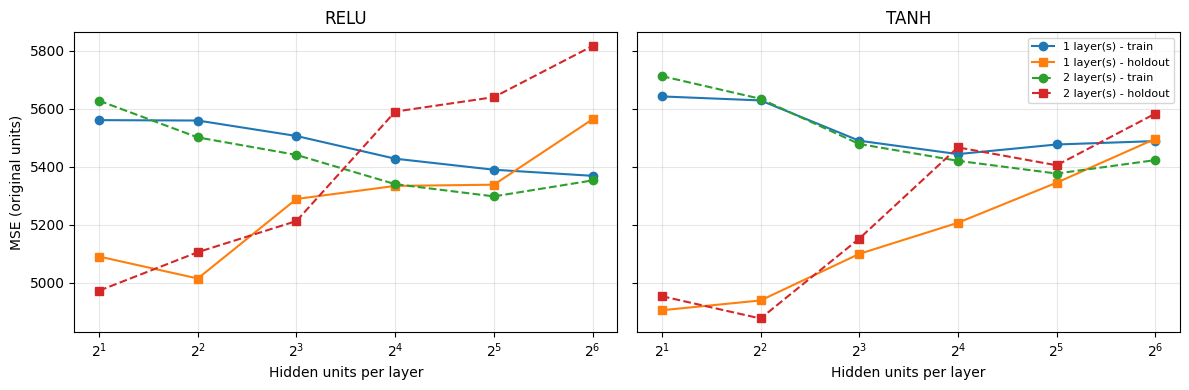

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, act in zip(axes, ["relu", "tanh"]):
    for n_layers, style in [(1, "-"), (2, "--")]:
        sub = results_df[(results_df.activation == act) & (results_df.hidden_layers == n_layers)]
        ax.plot(sub.hidden_units, sub.train_MSE, style, marker="o", label=f"{n_layers} layer(s) - train")
        ax.plot(sub.hidden_units, sub.holdout_MSE, style, marker="s", label=f"{n_layers} layer(s) - holdout")
    ax.set_xscale("log", base=2)
    ax.set_title(f"{act.upper()}")
    ax.set_xlabel("Hidden units per layer")
    ax.grid(alpha=0.3)
axes[0].set_ylabel("MSE (original units)")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

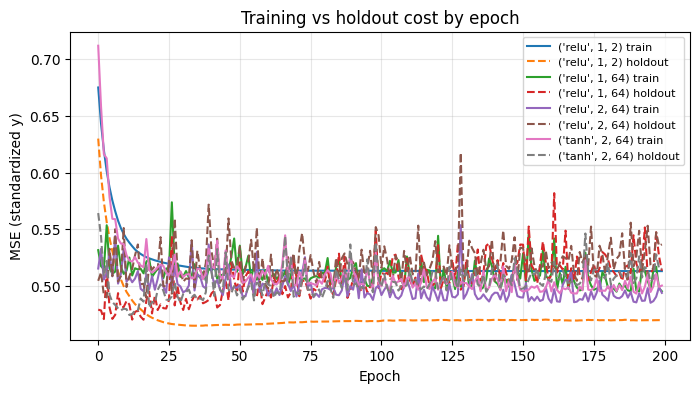

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
for key in [("relu", 1, 2), ("relu", 1, 64), ("relu", 2, 64), ("tanh", 2, 64)]:
    m = models[key]
    ax.plot(m.history["train_cost"], label=f"{key} train")
    ax.plot(m.history["val_cost"], "--", label=f"{key} holdout")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (standardized y)")
ax.set_title("Training vs holdout cost by epoch")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.show()

**How does the number of hidden units affect performance?**

With one ReLU layer, the training MSE kept going down as we added more units (from 5,560 with 2 units to 5,369 with 64). The holdout MSE went up instead: about 5,015 to 5,090 with 2 to 4 units, and 5,563 with 64 units. The gap between holdout and training went from about -470 to +195. This is overfitting. The bigger models have more flexibility, so they start fitting the noise in the training data, and that doesn’t carry over to new data. The actual relationship in this data is linear, so a really small network (2 or 4 units) was enough, and those did the best on the holdout set.

**What changes when using two layers instead of one?**

Adding a second layer mostly just adds more capacity, kind of like adding more units. With very few units (2 or 4), two layers did about the same as one, and sometimes a little better (ReLU with 2 units: 4,973 vs 5,091). With more units, two layers overfit more. For ReLU with 64 units, holdout MSE went from 5,563 with one layer to 5,810 with two, and the gap more than doubled (+195 to +458). Extra depth helps when the data has a complicated structure. This data is linear, so the second layer mostly made the model fit more noise.

**How does the activation function (ReLU vs. Tanh) influence results?**

Tanh did a bit better than ReLU in almost every setup, and its results were more consistent. Our best model overall was Tanh with 2 layers of 4 units each (holdout MSE of 4,877, R² of 0.555). Tanh’s train/holdout gaps also stayed smaller as the models got bigger. With 2 layers and 64 units, the gap was +160 for Tanh vs +458 for ReLU. We think this is because Tanh is smooth and almost linear near zero, and since our inputs are standardized, a lot of the values fall in that range. That makes it a good fit for data that’s close to linear. ReLU builds the function out of straight pieces with sharp corners, which makes it easier to fit small bumps in the data that are really just noise. The differences were pretty small, though, so the size of the model mattered more than the activation function.

## 4. Discussion (5 points)

You created a separate class for each task and likely repeated much of the same code across implementations.

Discuss within your group how could you have leveraged inheritance to make your code more reusable and avoid duplication. Provide examples. Be specific.

YOUR TEXT HERE

## 5. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

YOUR TEXT HERE